## 20\_optimisation

# 20 · Priorisation des emplacements sous contrainte budgétaire

**Objectif 3.** Produire une liste priorisée d'emplacements (stations Citiz, stations de vélos, arrêts de bus) qui maximise le nombre d'habitants nouvellement desservis à 5 minutes à pied, pour un budget donné.

**Méthode.** Couverture maximale par algorithme glouton : à chaque itération, l'emplacement retenu est celui qui apporte le plus d'habitants non encore desservis par euro investi. L'offre existante est déduite au départ, et un habitant couvert par deux emplacements n'est compté qu'une fois. L'ordre de sélection constitue la priorisation.

Chaque type d'équipement dispose de son propre budget, les financeurs étant distincts (Citiz pour l'autopartage, la Métropole pour les vélos et les arrêts de bus).

| Type | Emplacements candidats | Habitants comptabilisés |
| --- | --- | --- |
| Station Citiz | tout carreau habité | habitants sans station Citiz à 5 min, pondérés par le potentiel de leur carreau de résidence (notebook 12) |
| Station de vélos | tout carreau habité | habitants sans station Lovélo à 5 min |
| Arrêt de bus | carreau traversé par une ligne Astuce sans arrêt à 5 min | habitants sans aucun arrêt de transport à 5 min |

**Entrées :** `carreaux_rouen`, `options_rouen`, `carreaux_sur_lignes` (notebook 02) ; `zones_5min`, `couverture_candidats` (notebook 03) ; `scores_rouen`, `stats_citiz` (notebook 12, facultatives).

**Sorties :** `recommandations_rouen` (liste priorisée par scénario), `synthese_scenarios` (indicateurs agrégés), carte `Files/traite/cartes/recommandations_base.png`.

In [ ]:
# 1. Dépendances
%pip install -q geopandas pyogrio

Note: you may need to restart the kernel to use updated packages.


In [ ]:
# 2. Outils communs
import os, re, glob, shutil, tempfile, warnings
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

BASE = "/lakehouse/default/Files"
if not os.path.isdir(BASE):
    raise RuntimeError("Lakehouse par défaut non attaché : attacher le Lakehouse mobilite au notebook.")
BRUT = os.path.join(BASE, "brut")
TRAITE = os.path.join(BASE, "traite")
CARTES = os.path.join(TRAITE, "cartes")
os.makedirs(CARTES, exist_ok=True)

def _copier_csv(df, chemin):
    """Écrit le CSV en local, puis le copie dans le Lakehouse. Écrire directement dans OneLake échoue parfois
    quand le fichier existe déjà (« Unable to rename file »)."""
    fd, tmp = tempfile.mkstemp(suffix=".csv")
    os.close(fd)
    try:
        df.to_csv(tmp, index=False)
        if os.path.exists(chemin):
            os.remove(chemin)
        shutil.copyfile(tmp, chemin)
    finally:
        os.remove(tmp)

def _adresse_table(nom):
    """Adresse OneLake de la table dans le Lakehouse attaché, dans le schéma dbo s'il existe."""
    import notebookutils
    ctx = notebookutils.runtime.context
    espace = ctx.get("defaultLakehouseWorkspaceId") or ctx.get("currentWorkspaceId")
    lakehouse = ctx.get("defaultLakehouseId")
    if not (espace and lakehouse):
        raise RuntimeError("Lakehouse par défaut introuvable : attacher le Lakehouse mobilite au notebook")
    schema = "/dbo" if os.path.isdir("/lakehouse/default/Tables/dbo") else ""
    return f"abfss://{espace}@onelake.dfs.fabric.microsoft.com/{lakehouse}/Tables{schema}/{nom}"

def _ecrire_table(df, nom):
    """Table Delta lue par Power BI. Noyau Spark : saveAsTable. Noyau Python : bibliothèque deltalake."""
    try:
        spark  # n'existe que dans le noyau Spark
    except NameError:
        import pyarrow as pa
        import notebookutils
        from deltalake import write_deltalake
        donnees = pa.Table.from_pandas(df, preserve_index=False)
        options = {"bearer_token": notebookutils.credentials.getToken("storage"), "use_fabric_endpoint": "true"}
        try:
            write_deltalake(_adresse_table(nom), donnees, mode="overwrite", schema_mode="overwrite",
                            storage_options=options)
        except TypeError:   # anciennes versions de deltalake
            write_deltalake(_adresse_table(nom), donnees, mode="overwrite", overwrite_schema=True,
                            storage_options=options)
        return
    spark.createDataFrame(df).write.mode("overwrite").option("overwriteSchema", "true").saveAsTable(nom)

def enregistrer(df, nom):
    """Enregistre un tableau en CSV dans Files/traite (relu par les autres notebooks)
    et en table du Lakehouse (lue par Power BI), avec le noyau Python comme avec le noyau Spark."""
    df = df.reset_index(drop=True).copy()
    _copier_csv(df, os.path.join(TRAITE, nom + ".csv"))
    for c in df.columns:
        if not (pd.api.types.is_numeric_dtype(df[c]) or pd.api.types.is_bool_dtype(df[c])):
            df[c] = df[c].map(lambda v: None if v is None or (isinstance(v, float) and np.isnan(v)) else str(v))
    try:
        _ecrire_table(df, nom)
        print(f"   table {nom} : {len(df)} lignes (copie dans Files/traite/{nom}.csv)")
    except Exception as e:
        print(f"   {nom}.csv : {len(df)} lignes. ATTENTION, table non créée pour Power BI : {e}")

def nb(n):
    """Écrit un nombre avec des espaces entre les milliers : 12 345."""
    return f"{n:,.0f}".replace(",", " ")

def existe(nom):
    return os.path.exists(os.path.join(TRAITE, nom + ".csv"))

def lire(nom):
    """Relit un tableau enregistré par un autre notebook."""
    chemin = os.path.join(TRAITE, nom + ".csv")
    if not os.path.exists(chemin):
        raise FileNotFoundError(f"{nom}.csv introuvable dans Files/traite : exécuter d'abord le notebook qui le produit.")
    return pd.read_csv(chemin, dtype={"idcar": str, "commune": str, "idcar_1km": str, "candidat": str})

def charger_territoire(court):
    """Contour de l'intercommunalité (Lambert-93) et ses communes (fichiers IGN du notebook 01)."""
    import geopandas as gpd
    epci = gpd.read_file(os.path.join(BRUT, f"epci_{court}.geojson")).to_crs(2154)
    communes = gpd.read_file(os.path.join(BRUT, f"communes_{court}.geojson")).to_crs(2154)
    communes = communes[["code_insee", "nom_officiel", "geometry"]].rename(
        columns={"code_insee": "commune", "nom_officiel": "commune_nom"})
    return epci.geometry.iloc[0], communes

In [ ]:
# 3. Paramètres
MODE_ESSAI = False          # True : exemple jouet de 5 carreaux illustrant l'algorithme. False : données de Rouen
UTILISER_SCORES = "True"    # "auto" : potentiel du notebook 12 s'il existe. True : obligatoire. False : habitants seuls
PART_EQUITE = 0.20          # part de chaque budget réservée aux communes peu denses (scénario « équité »)

# Budget maximal par type d'équipement, en euros
BUDGETS = {"Station Citiz": 1_500_000, "Station de vélos": 10_000_000, "Arrêt de bus": 800_000}

# Coût unitaire par type d'équipement, en euros (première année), en fourchette basse, moyenne et haute.
# La source est reportée dans la table de sortie, à côté de chaque coût.
COUTS = {
    # Véhicule et place : 25 k€ par véhicule (Voreppe, conseil municipal du 21/10/2021) ; prix moyen d'une voiture
    # neuve 36,7 k€ en 2024 (Roole, AAA Data) ; aménagement de station minime (livre blanc Citiz 2026)
    "Station Citiz":    {"bas": 20_000, "moyen": 25_000, "haut": 32_000,
                         "source": "Voreppe CM 21/10/2021 ; prix moyen voiture neuve 2024 (Roole, AAA Data) ; livre blanc Citiz 2026"},
    # Cerema 2019 : 1 900 à 2 500 € HT par vélo, stations comprises (3 000 à 3 500 € en VAE) ; 7 à 10 vélos par station
    "Station de vélos": {"bas": 13_000, "moyen": 25_000, "haut": 35_000,
                         "source": "Cerema 2019, VLS avec station ; 7 à 10 vélos par station"},
    # Cerema : environ 15 k€ TTC par arrêt rendu accessible ; SDA-Ad'AP BFC : 10 k€ HT ; abri voyageurs 1,3 à 9,2 k€
    "Arrêt de bus":     {"bas": 10_000, "moyen": 15_000, "haut": 25_000,
                         "source": "Cerema, points d'arrêt accessibles ; SDA-Ad'AP Bourgogne-Franche-Comté ; abri voyageurs"},
}

# Données Citiz (énoncé) : utilisées si la table stats_citiz est absente
CONDUCTEURS_CITIZ, VOITURES_CITIZ = 130_000, 2_800

In [ ]:
# 4. Algorithme glouton de couverture maximale
import heapq

def choisir(candidats, couverture, valeur_carreau, deja, cout, budget, autorise=None, depense=0.0, retenus=None):
    """Choisit des emplacements, du plus rentable au moins rentable, jusqu'au budget.
    candidats : liste d'emplacements ; couverture[emplacement] : carreaux desservis à 5 minutes à pied ;
    valeur_carreau[carreau] : ce que rapporte ce carreau s'il devient desservi (ses habitants, pondérés ou non) ;
    deja : carreaux déjà desservis, mis à jour au fil des choix ; autorise(emplacement) : filtre facultatif.
    Le coût est le même pour tous les emplacements d'un type : classer par valeur revient à classer par valeur par euro."""
    retenus = set() if retenus is None else retenus
    def valeur(c):
        return sum(valeur_carreau.get(k, 0) for k in couverture[c] if k not in deja)
    file = []
    for c in candidats:
        if c not in retenus and (autorise is None or autorise(c)):
            v = valeur(c)
            if v > 0:
                heapq.heappush(file, (-v, c))
    choix = []
    while file and depense + cout <= budget:
        _, c = heapq.heappop(file)
        v = valeur(c)                                # valeur recalculée : des voisins ont pu être choisis entre-temps
        if v <= 0:
            continue
        if file and v < -file[0][0]:                 # elle a baissé : il remet sa place en jeu
            heapq.heappush(file, (-v, c))
            continue
        nouveaux = [k for k in couverture[c] if k not in deja]
        deja.update(nouveaux)
        depense += cout
        retenus.add(c)
        choix.append({"emplacement": c, "valeur": v, "nouveaux": nouveaux, "cout": cout, "cout_cumule": depense})
    return choix, depense

In [ ]:
# 5. Exemple jouet : 5 carreaux, stations à 30 000 €, budget de 70 000 €
if MODE_ESSAI:
    habitants = {"A": 400, "B": 300, "C": 250, "D": 100, "E": 50}
    couverture = {"A": ["A", "B"], "C": ["C", "B"], "E": ["E", "D"]}
    print("Valeurs initiales : A = 700 habitants (A et B), C = 550 (C et B), E = 150 (E et D)")
    choix, total = choisir(list(couverture), couverture, habitants, set(), 30_000, 70_000)
    for rang, ch in enumerate(choix, 1):
        print(f"Itération {rang} : station en {ch['emplacement']}, +{ch['valeur']:.0f} habitants ({', '.join(ch['nouveaux'])}), "
              f"dépense cumulée {nb(ch['cout_cumule'])} €")
    print("Après l'itération 1, les habitants de B sont couverts : la valeur de C passe de 550 à 250, toujours devant E (150).")
    print("Le reliquat de 10 000 € ne finance pas de station supplémentaire.")

In [ ]:
# 6. Données de Rouen : habitants, offre existante, candidats, potentiel
if not MODE_ESSAI:
    requis = {"carreaux_rouen": "02", "options_rouen": "02", "carreaux_sur_lignes": "02",
              "zones_5min": "03", "couverture_candidats": "03"}
    manquants = [f"{nom} (notebook {source})" for nom, source in requis.items() if not existe(nom)]
    if manquants:
        raise RuntimeError("Entrées manquantes : " + ", ".join(manquants) + ".")

    carreaux = lire("carreaux_rouen")
    options = lire("options_rouen")
    zones = lire("zones_5min").merge(options[["option_id", "type"]], on="option_id")
    couv = lire("couverture_candidats")
    sur_lignes = set(lire("carreaux_sur_lignes")["idcar"])
    habitants = carreaux.set_index("idcar")["population"].astype(float).to_dict()
    couverture = couv.groupby("candidat")["idcar"].apply(list).to_dict()
    for k in habitants:
        couverture.setdefault(k, [k])

    # Potentiel Citiz de chaque carreau (0 à 1), du notebook 12
    utiliser_scores = existe("scores_rouen") if UTILISER_SCORES == "auto" else UTILISER_SCORES
    if utiliser_scores:
        notes = lire("scores_rouen").set_index("idcar")["potentiel"] / 100
        potentiel = {k: float(notes.get(k, 0.0)) for k in habitants}
        print(f"Potentiel Citiz lu pour {sum(k in notes.index for k in habitants)} carreaux sur {len(habitants)}")
    else:
        potentiel = {k: 1.0 for k in habitants}
        print("scores_rouen absent : stations Citiz classées par habitants, sans pondération par le potentiel.")

    # Taux d'adhésion observé dans les villes Citiz (notebook 12)
    if existe("stats_citiz"):
        stats = lire("stats_citiz").iloc[0]
        TAUX_ADHESION, PAR_VOITURE = float(stats["taux_adhesion"]), float(stats["conducteurs_par_voiture"])
    else:
        TAUX_ADHESION, PAR_VOITURE = np.nan, CONDUCTEURS_CITIZ / VOITURES_CITIZ
        print("stats_citiz absent : abonnés et voitures non calculés.")

    transports = {"Bus", "TEOR", "Métro", "Gare TER", "Train"}
    offre = {
        "Station Citiz": set(),                                                        # pas de Citiz à Rouen
        "Station de vélos": set(zones.loc[zones["type"] == "Vélo en libre-service", "idcar"]),
        "Arrêt de bus": set(zones.loc[zones["type"].isin(transports), "idcar"]),
    }
    candidats = {
        "Station Citiz": list(habitants),
        "Station de vélos": list(habitants),
        "Arrêt de bus": [k for k in habitants if k in sur_lignes and k not in offre["Arrêt de bus"]],
    }

    # Commune de chaque carreau d'après son centre et les contours IGN 2026 (les codes Filosofi suivent la géographie 2021)
    import geopandas as gpd
    contour, communes = charger_territoire("rouen")
    points = gpd.GeoDataFrame(carreaux[["idcar"]], geometry=gpd.points_from_xy(carreaux["x"], carreaux["y"]), crs=2154)
    rattache = gpd.sjoin(points, communes[["commune", "commune_nom", "geometry"]], how="left", predicate="within")
    rattache = rattache[~rattache.index.duplicated()].reindex(points.index)
    carreaux["commune"] = rattache["commune"].fillna(carreaux["commune"]).values
    carreaux["commune_nom"] = rattache["commune_nom"].fillna(carreaux["commune_nom"]).values

    # Communes peu denses : densité sous la médiane des communes habitées de la Métropole
    communes["densite"] = communes["commune"].map(carreaux.groupby("commune")["population"].sum()).fillna(0) / (communes.geometry.area / 1e6)
    habitees = communes[communes["densite"] > 0]
    peu_denses = set(habitees.loc[habitees["densite"] < habitees["densite"].median(), "commune"])
    commune_de = carreaux.set_index("idcar")["commune"].to_dict()

    for t, liste in candidats.items():
        print(f"{t} : {nb(len(liste))} emplacements candidats, {nb(sum(habitants[k] for k in offre[t]))} habitants déjà desservis")
    print(f"Communes peu denses (scénario équité) : {len(peu_denses)} sur {len(communes)}")

Potentiel Citiz lu pour 5727 carreaux sur 5727
Station Citiz : 5 727 emplacements candidats, 0 habitants déjà desservis
Station de vélos : 5 727 emplacements candidats, 102 780 habitants déjà desservis
Arrêt de bus : 374 emplacements candidats, 345 082 habitants déjà desservis
Communes peu denses (scénario équité) : 35 sur 71


In [ ]:
# 7. Scénarios
if not MODE_ESSAI:
    TYPES = list(BUDGETS)
    SCENARIOS = [  # nom, niveau de coût, équité, potentiel utilisé, types concernés
        ("Base, coûts moyens", "moyen", False, True, TYPES),
        ("Équité : 20 % pour les communes peu denses", "moyen", True, True, TYPES),
        ("Coûts hauts", "haut", False, True, TYPES),
        ("Coûts bas", "bas", False, True, TYPES),
        ("Sans le modèle (habitants seuls)", "moyen", False, False, ["Station Citiz"]),
    ]

    def lancer(nom, niveau, equite, avec_modele, types):
        lignes = []
        for t in types:
            pondere = t == "Station Citiz" and avec_modele and utiliser_scores
            valeur_carreau = {k: habitants[k] * (potentiel[k] if pondere else 1.0) for k in habitants}
            deja, retenus, depense, choix = set(offre[t]), set(), 0.0, []
            cout, budget = COUTS[t][niveau], BUDGETS[t]
            etapes = [(PART_EQUITE * budget, lambda c: commune_de.get(c) in peu_denses)] if equite else []
            for plafond, filtre in etapes + [(budget, None)]:
                res, depense = choisir(candidats[t], couverture, valeur_carreau, deja, cout, plafond, filtre, depense, retenus)
                choix += res
            cumul = 0
            for rang, ch in enumerate(choix, 1):
                gagnes = sum(habitants.get(k, 0) for k in ch["nouveaux"])
                cumul += gagnes
                citiz = t == "Station Citiz"
                abonnes = cumul * TAUX_ADHESION if citiz else np.nan
                lignes.append({
                    "scenario": nom, "type": t, "rang": rang, "idcar": ch["emplacement"],
                    "commune": commune_de.get(ch["emplacement"]),
                    "habitants_gagnes": round(gagnes), "habitants_cumules": round(cumul),
                    "habitants_ponderes": round(ch["valeur"]),
                    "potentiel": round(100 * potentiel.get(ch["emplacement"], 0.0), 1) if citiz and utiliser_scores else np.nan,
                    "cout": float(ch["cout"]), "cout_cumule": float(ch["cout_cumule"]),
                    "abonnes_cumules": round(abonnes) if citiz and np.isfinite(abonnes) else np.nan,
                    "voitures_cumulees": round(abonnes / PAR_VOITURE, 1) if citiz and np.isfinite(abonnes) else np.nan,
                    "source_cout": COUTS[t]["source"],
                })
        return pd.DataFrame(lignes)

    reco = pd.concat([lancer(*s) for s in SCENARIOS], ignore_index=True)
    pos = carreaux.set_index("idcar")
    reco["lat"], reco["lon"] = reco["idcar"].map(pos["lat"]), reco["idcar"].map(pos["lon"])
    reco["commune_nom"] = reco["idcar"].map(pos["commune_nom"])

    # Contrôles : pas d'emplacement en double, budget jamais dépassé
    assert not reco.duplicated(["scenario", "type", "idcar"]).any(), "emplacement choisi deux fois"
    assert (reco["cout_cumule"] <= reco["type"].map(BUDGETS) + 1e-6).all(), "budget dépassé"

    print("Enregistrement :")
    enregistrer(reco, "recommandations_rouen")

Enregistrement :
   table recommandations_rouen : 2373 lignes (copie dans Files/traite/recommandations_rouen.csv)


   table synthese_scenarios : 13 lignes (copie dans Files/traite/synthese_scenarios.csv)

Tous les scénarios, au budget maximal :
                                  scenario             type  emplacements  cout_total  habitants_gagnes  abonnes  voitures  potentiel_moyen
                        Base, coûts moyens    Station Citiz            60   1500000.0            129618   5081.0     109.5             92.8
                        Base, coûts moyens Station de vélos           400  10000000.0            257537      NaN       NaN              NaN
                        Base, coûts moyens     Arrêt de bus            53    795000.0             14383      NaN       NaN              NaN
Équité : 20 % pour les communes peu denses    Station Citiz            60   1500000.0            118718   4654.0     100.3             87.3
Équité : 20 % pour les communes peu denses Station de vélos           400  10000000.0            254627      NaN       NaN              NaN
Équité : 20 % pour les commune

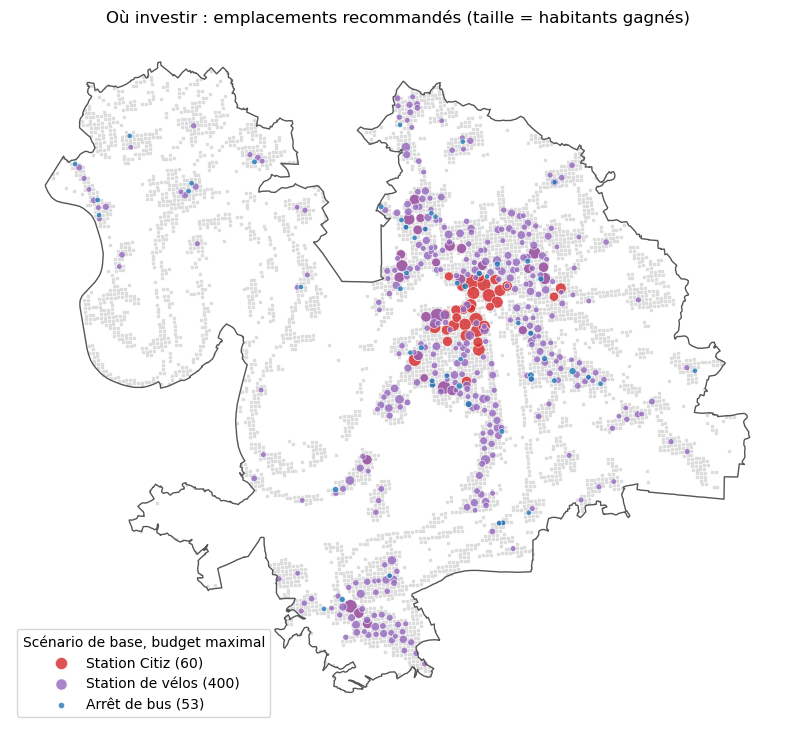

In [ ]:
# 8. Synthèse des scénarios et carte du scénario de base
if not MODE_ESSAI:
    synthese = (reco.groupby(["scenario", "type"], sort=False)
                    .agg(emplacements=("rang", "size"), cout_total=("cout", "sum"),
                         habitants_gagnes=("habitants_gagnes", "sum"), abonnes=("abonnes_cumules", "max"),
                         voitures=("voitures_cumulees", "max"), potentiel_moyen=("potentiel", "mean"))
                    .round(1).reset_index())
    enregistrer(synthese, "synthese_scenarios")
    print("\nTous les scénarios, au budget maximal :")
    print(synthese.to_string(index=False))

    base = reco[reco["scenario"] == SCENARIOS[0][0]]
    print("\nLes 10 premières stations Citiz du scénario de base :")
    print(base[base["type"] == "Station Citiz"].head(10)[["rang", "commune_nom", "habitants_gagnes", "potentiel", "cout_cumule"]].to_string(index=False))

    if utiliser_scores:
        avec = set(base.loc[base["type"] == "Station Citiz", "idcar"])
        sans = set(reco.loc[reco["scenario"] == SCENARIOS[-1][0], "idcar"])
        print(f"\nEffet du modèle : {len(avec & sans)} stations Citiz sur {len(avec)} sont communes aux scénarios "
              f"avec et sans pondération par le potentiel.")

    import matplotlib.pyplot as plt
    from pyproj import Transformer
    x, y = Transformer.from_crs(4326, 2154, always_xy=True).transform(base["lon"].values, base["lat"].values)
    couleurs = {"Station Citiz": "#d62728", "Station de vélos": "#9467bd", "Arrêt de bus": "#1f77b4"}
    fig, ax = plt.subplots(figsize=(10, 10))
    gpd.GeoSeries([contour], crs=2154).boundary.plot(ax=ax, color="#555555", linewidth=1)
    ax.scatter(carreaux["x"], carreaux["y"], s=2, color="#dddddd", marker="s")
    for t, coul in couleurs.items():
        g = base["type"].values == t
        ax.scatter(x[g], y[g], s=10 + base.loc[g, "habitants_gagnes"] / 40, color=coul, alpha=0.8,
                   edgecolor="white", linewidth=0.5, label=f"{t} ({g.sum()})")
    ax.legend(title="Scénario de base, budget maximal", loc="lower left")
    ax.set_title("Où investir : emplacements recommandés (taille = habitants gagnés)")
    ax.set_axis_off()
    plt.savefig(os.path.join(CARTES, "recommandations_base.png"), dpi=130, bbox_inches="tight")
    plt.show()

## Description des sorties

**`recommandations_rouen`** : une ligne par emplacement retenu, dans l'ordre de priorité.

| Colonne | Contenu |
| --- | --- |
| `scenario`, `type`, `rang` | scénario, type d'équipement, ordre de priorité |
| `idcar`, `commune_nom`, `lat`, `lon` | carreau INSEE de 200 m de l'emplacement |
| `habitants_gagnes`, `habitants_cumules` | habitants nouvellement à 5 minutes à pied, par emplacement et en cumul |
| `habitants_ponderes` | habitants pondérés par le potentiel (critère de sélection des stations Citiz) |
| `potentiel` | potentiel Citiz du carreau, de 0 à 100 |
| `cout`, `cout_cumule`, `source_cout` | coût unitaire, coût cumulé, source du coût |
| `abonnes_cumules`, `voitures_cumulees` | abonnés Citiz potentiels et voitures nécessaires, en cumul |

Un filtre sur `cout_cumule` restitue la liste des emplacements finançables pour tout budget inférieur au budget maximal.

**Scénarios.** *Base* : coûts moyens. *Équité* : 20 % de chaque budget réservés aux communes dont la densité est inférieure à la médiane. *Coûts hauts* et *Coûts bas* : bornes de la fourchette de coûts. *Sans le modèle* : stations Citiz classées par habitants seuls, pour mesurer l'apport du modèle prédictif.

## Hypothèses et limites

- Coût unitaire identique pour tous les emplacements d'un même type : les scénarios de coûts conservent l'ordre de priorité et ne modifient que le nombre d'emplacements financés.
- Le potentiel Citiz décrit la ressemblance avec les quartiers où Citiz est déjà implanté, et non une demande mesurée.
- Abonnés potentiels = habitants nouvellement desservis × taux d'adhésion observé autour des stations Citiz existantes. Ce taux est un majorant : une partie des abonnés réside au-delà de 400 m d'une station.
- L'algorithme glouton fournit une solution approchée du problème de couverture maximale, avec une garantie classique d'au moins 63 % de l'optimum.